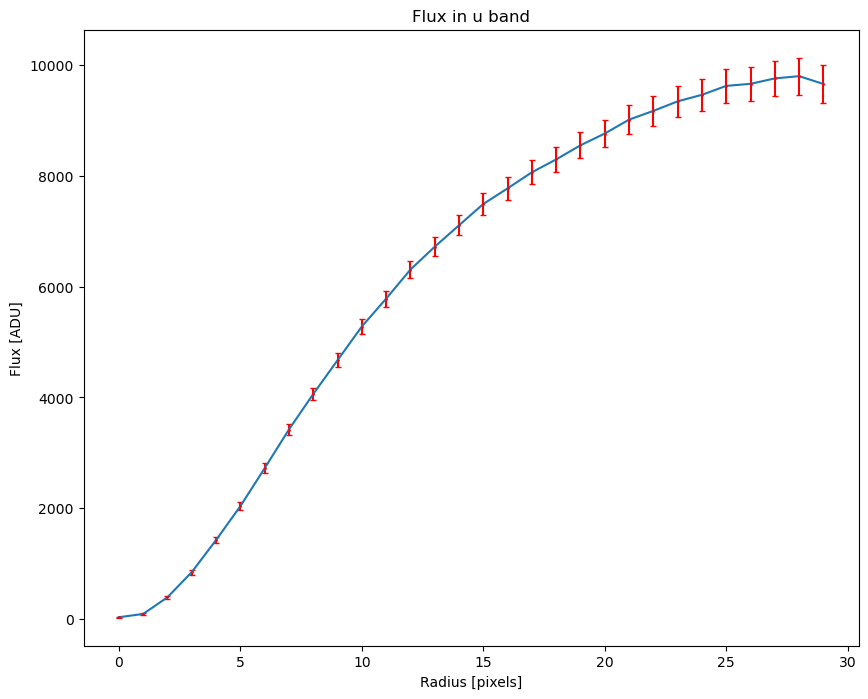

Galaxys flux in filter u is 16.794 ± 0.028 mag


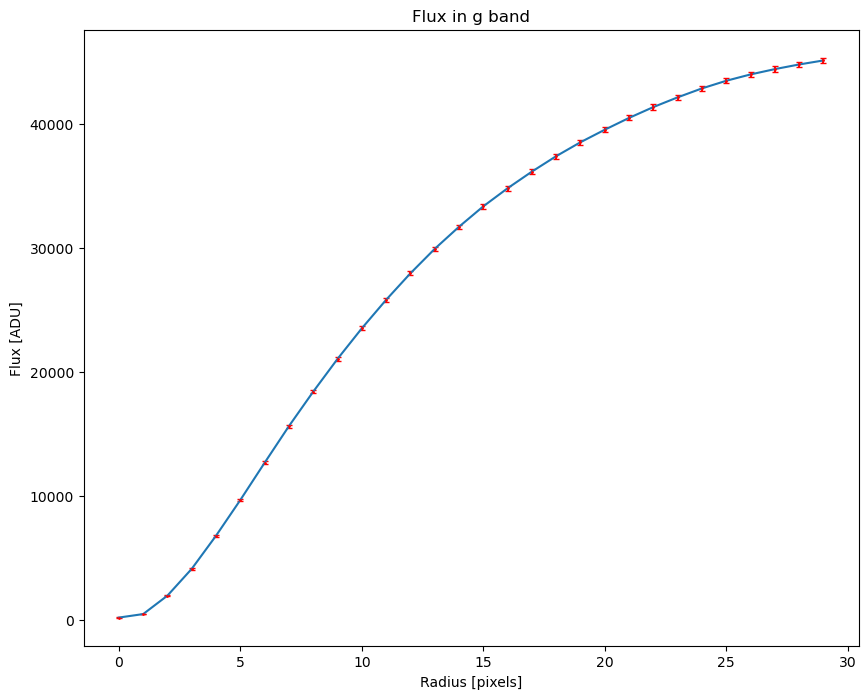

Galaxys flux in filter g is 17.114 ± 0.006 mag


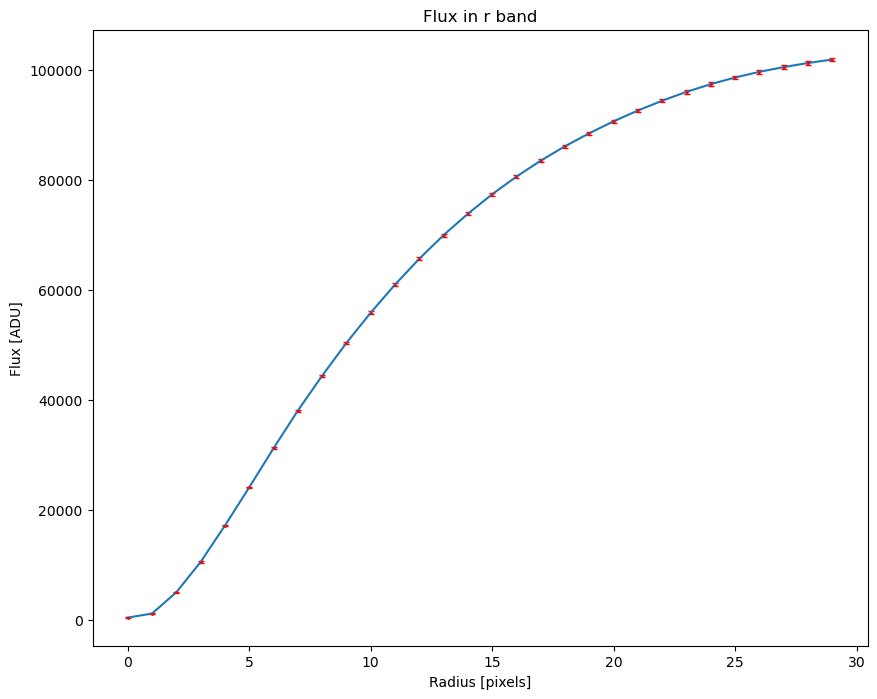

Galaxys flux in filter r is 16.055 ± 0.004 mag


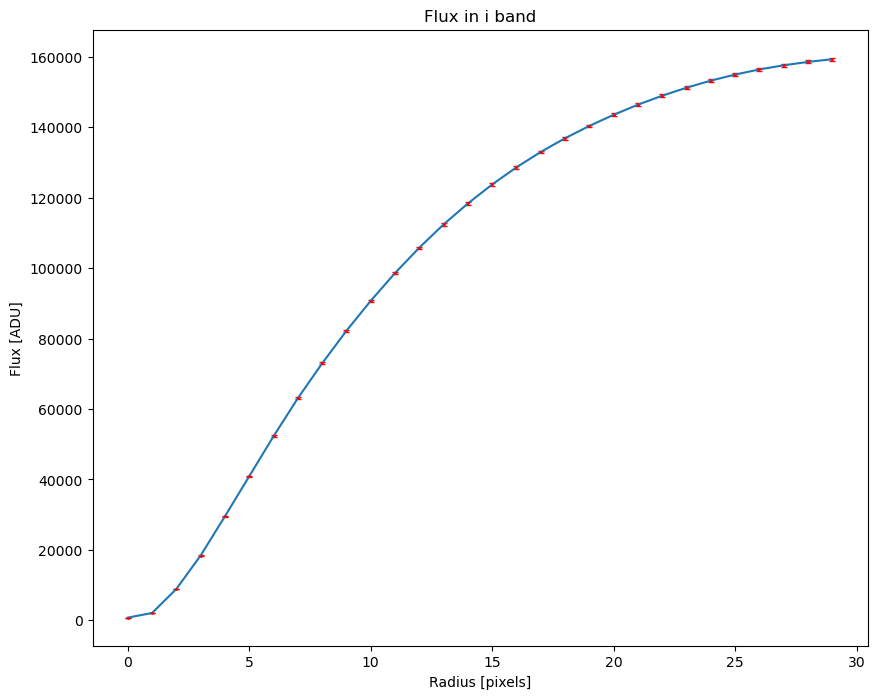

Galaxys flux in filter i is 15.397 ± 0.003 mag


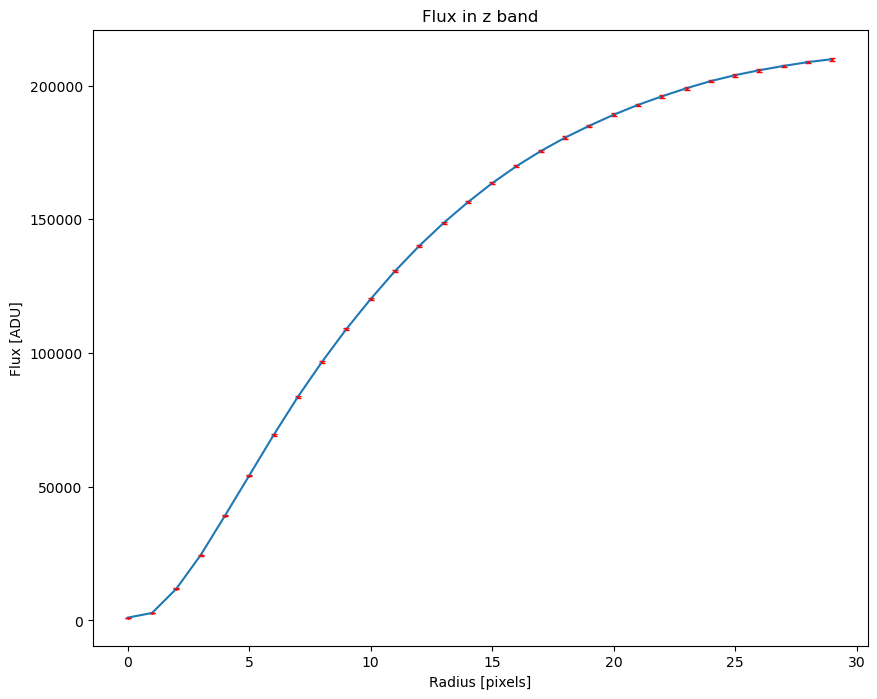

Galaxys flux in filter z is 14.705 ± 0.003 mag


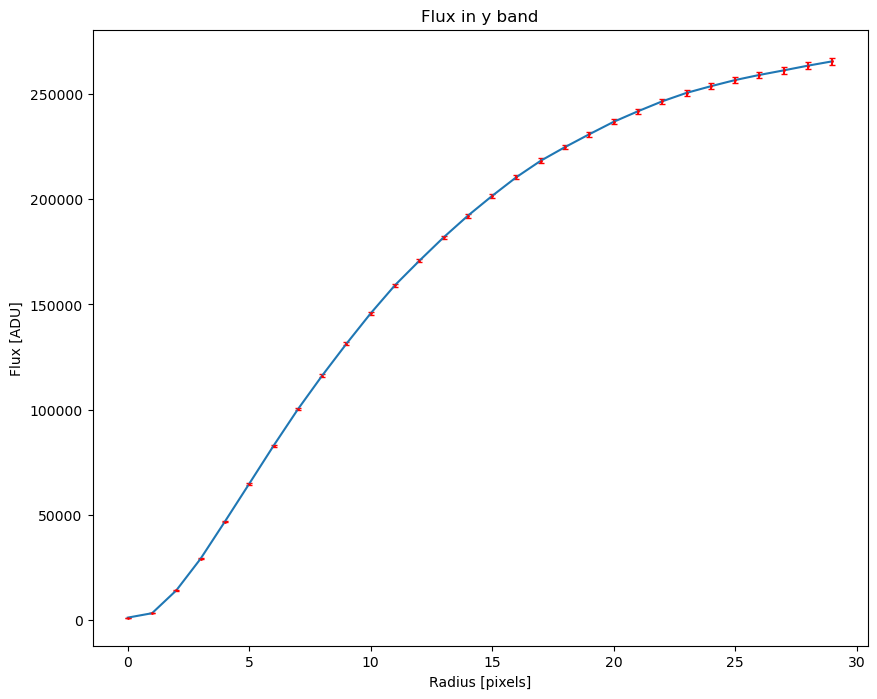

Galaxys flux in filter y is 13.472 ± 0.005 mag


In [12]:
from astropy.io import fits
import matplotlib.pyplot as plt
import numpy as np
import sep
from matplotlib import rcParams

%matplotlib inline

rcParams['figure.figsize'] = [10., 8.]

# Open FITS file
hdul = fits.open("galaxy_images.fits")

filter_names = ['u', 'g', 'r', 'i', 'z', 'y']

zp = [26.52, 28.51, 28.36, 28.17, 27.78, 26.82] # dla gain = 1.0 ze stony LSST: https://smtn-002.lsst.io/

radius_range = 30

# Image data
for filter in range(len(hdul) - 1):
    # Getting an image in this filter
    image = hdul[filter + 1].data
    data = image.astype(image.dtype.newbyteorder('='))

    # Background substraction
    bkg = sep.Background(data)
    bkg_rms = bkg.rms()
    data_sub = data - bkg

    # Getting different fluxes
    fluxes = np.zeros(radius_range)
    fluxerrs = np.zeros(radius_range)
    radiuses = np.zeros(radius_range)

    for i in range(radius_range):
        flux, fluxerr, flag = sep.sum_circle(data_sub, x=[75.0], y=[75.0], 
                                            r=i, err=bkg.globalrms, gain=1.0)
        
        fluxes[i] = flux[0]
        fluxerrs[i] = fluxerr[0]
        radiuses[i] = i

    # Ploting the flux 
    plt.errorbar(
        x=radiuses, y=fluxes,
        yerr=fluxerrs,
        markersize=1,
        fmt='o',
        color ='red',
        capsize=2
    )
    plt.plot(radiuses, fluxes)       

    plt.title(f"Flux in {filter_names[filter]} band")
    plt.xlabel("Radius [pixels]")
    plt.ylabel("Flux [ADU]")
    plt.show()

    # Picking radius and calculating 
    max_flux = fluxes[radius_range - 1]
    flux80 = 0.8 * max_flux
    j = 0
    while (fluxes[j] < flux80):
        j = j + 1
    radius80 = j

    mag = -2.5 * np.log10(fluxes[radius80]) + zp[filter]
    mag_err = (2.5 / np.log(10)) * (fluxerrs[radius80] / fluxes[radius80])

    print(f"Galaxys flux in filter {filter_names[filter]} is {mag:.3f} \u00B1 {mag_err:.3f} mag")